<a href="https://colab.research.google.com/github/laboratoriodecodigos/Colab-Python/blob/main/Prophet_Laboratorio_de_Codigos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🔮 Laboratorio de Códigos · Explorando Prophet (Meta)
Notebook de referencia: pronóstico de series de tiempo con **Prophet**. Cada sección muestra código + resultado. Todas las imágenes y el video se guardan en `/content/prophet_assets` y se descargan en un ZIP al final.

**Repo:** https://github.com/facebook/prophet

In [1]:
!pip install -q prophet plotly

In [2]:
import os, time, itertools, logging, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import prophet
from prophet import Prophet
from prophet.plot import (add_changepoints_to_plot, plot_cross_validation_metric,
                          plot_plotly, plot_components_plotly)
from prophet.diagnostics import cross_validation, performance_metrics
from prophet.utilities import regressor_coefficients, warm_start_params
from prophet.serialize import model_to_json, model_from_json

logging.getLogger('cmdstanpy').setLevel(logging.WARNING)
logging.getLogger('prophet').setLevel(logging.WARNING)
warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.figsize': (12, 6), 'axes.grid': True, 'font.size': 12})

OUT = '/content/prophet_assets'
os.makedirs(OUT, exist_ok=True)
def guardar(fig, nombre):
    fig.savefig(f'{OUT}/{nombre}.png', dpi=200, bbox_inches='tight')
    plt.show()

print('Prophet', prophet.__version__)

BASE = 'https://raw.githubusercontent.com/facebook/prophet/main/examples/'
df = pd.read_csv(BASE + 'example_wp_log_peyton_manning.csv')
df['ds'] = pd.to_datetime(df['ds'])
print(df.shape)
df.head()

Prophet 1.5.0
(2905, 2)


,ds,y
0,2007-12-10,9.590761
1,2007-12-11,8.519590
2,2007-12-12,8.183677
3,2007-12-13,8.072467
4,2007-12-14,7.893572


## 1️⃣ Lo básico: `fit` → `make_future_dataframe` → `predict` → `plot`
Prophet exige dos columnas: `ds` (fecha) y `y` (valor).

,ds,yhat,yhat_lower,yhat_upper
3265,2017-01-15,8.207812,7.484141,8.923495
3266,2017-01-16,8.532840,7.784514,9.258257
3267,2017-01-17,8.320255,7.602251,9.043981
3268,2017-01-18,8.152877,7.364134,8.861699
3269,2017-01-19,8.164830,7.427204,8.872988


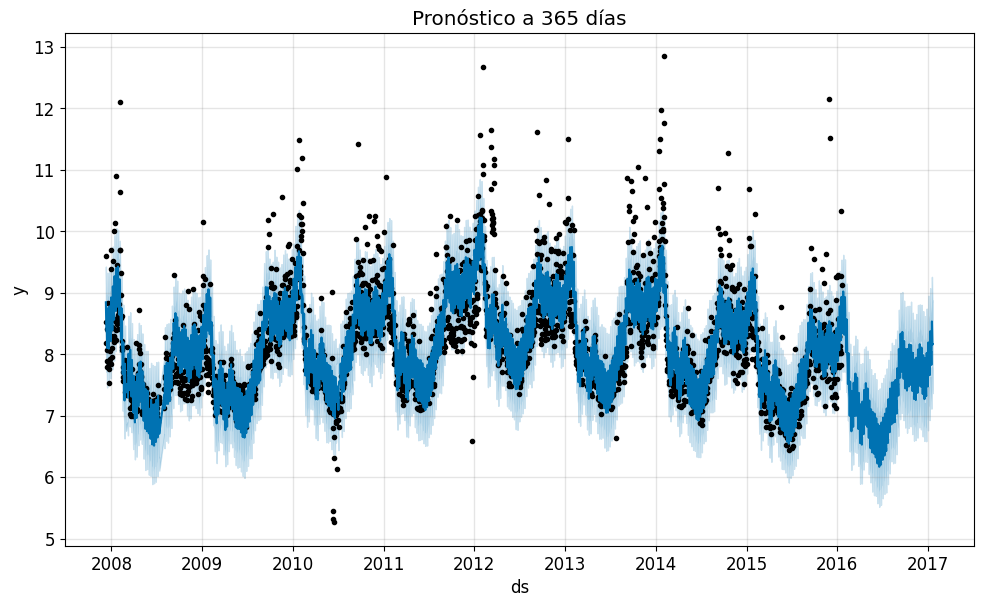

In [3]:
m = Prophet()
m.fit(df)
future = m.make_future_dataframe(periods=365)
forecast = m.predict(future)
display(forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail())

fig = m.plot(forecast)
plt.title('Pronóstico a 365 días')
guardar(fig, '01_pronostico')

## 2️⃣ Componentes: tendencia + estacionalidad semanal + anual

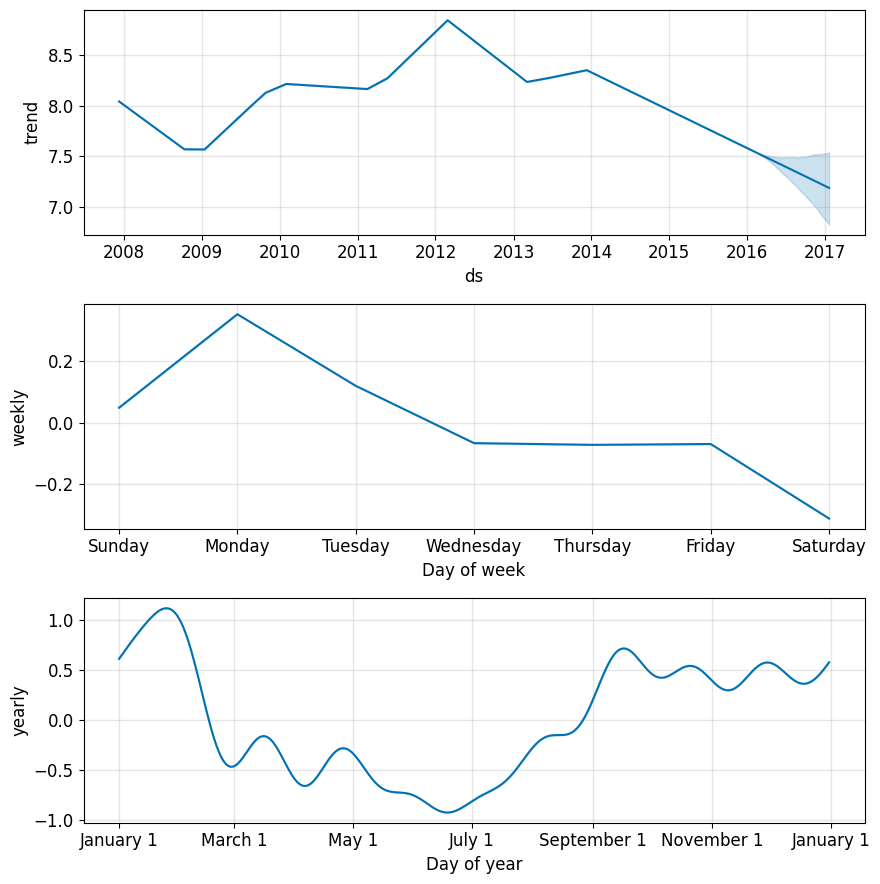

In [4]:
fig = m.plot_components(forecast)
guardar(fig, '02_componentes')

## 3️⃣ Puntos de cambio (changepoints)
Dónde cambia la tendencia y qué tan flexible es: `changepoint_prior_scale`, `n_changepoints`, `changepoint_range` o una lista manual `changepoints=[...]`.

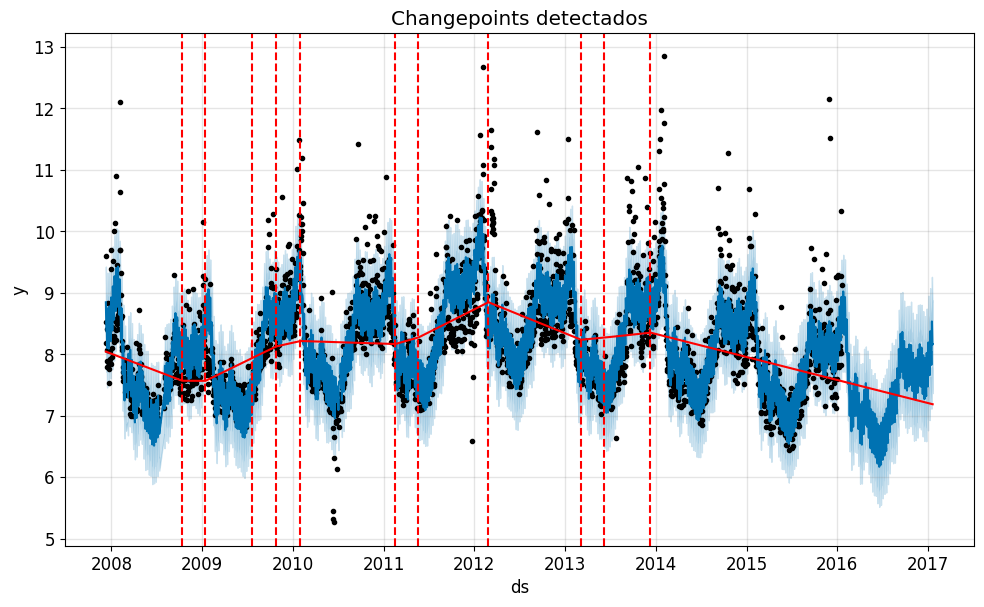

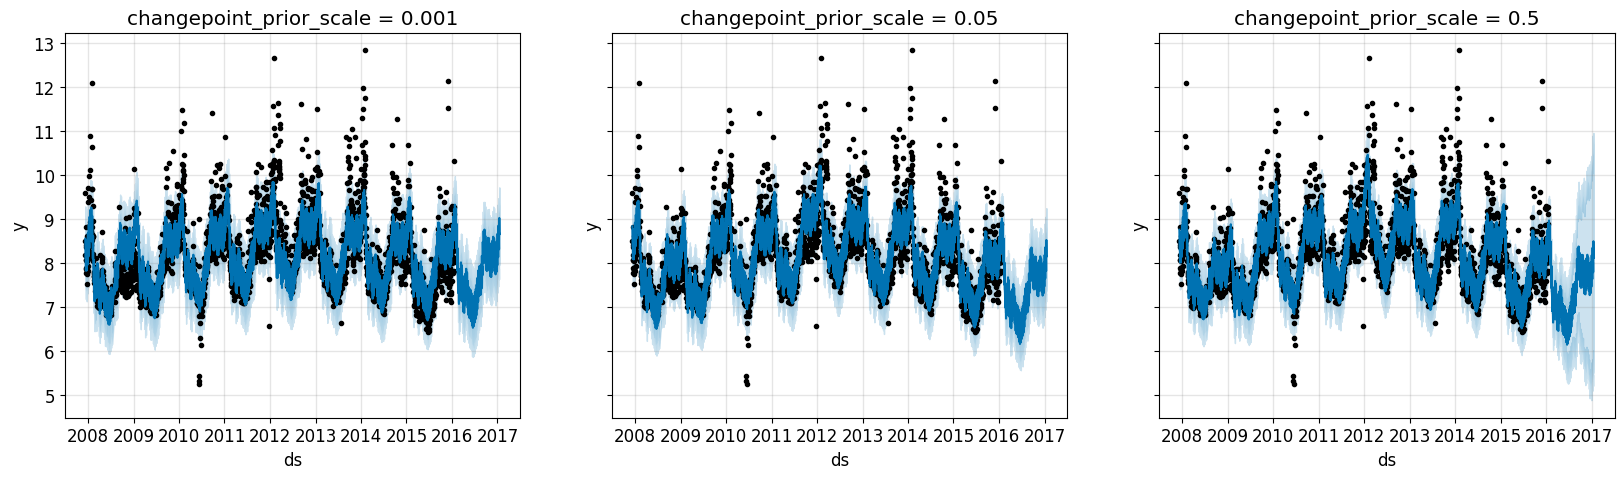

In [5]:
fig = m.plot(forecast)
add_changepoints_to_plot(fig.gca(), m, forecast)
plt.title('Changepoints detectados')
guardar(fig, '03_changepoints')

fig, axes = plt.subplots(1, 3, figsize=(20, 5), sharey=True)
for ax, cps in zip(axes, [0.001, 0.05, 0.5]):
    mm = Prophet(changepoint_prior_scale=cps).fit(df)
    fc = mm.predict(mm.make_future_dataframe(365))
    mm.plot(fc, ax=ax)
    ax.set_title(f'changepoint_prior_scale = {cps}')
guardar(fig, '04_changepoint_scale')

## 4️⃣ Tipos de crecimiento: `linear`, `logistic` (techo y piso) y `flat`

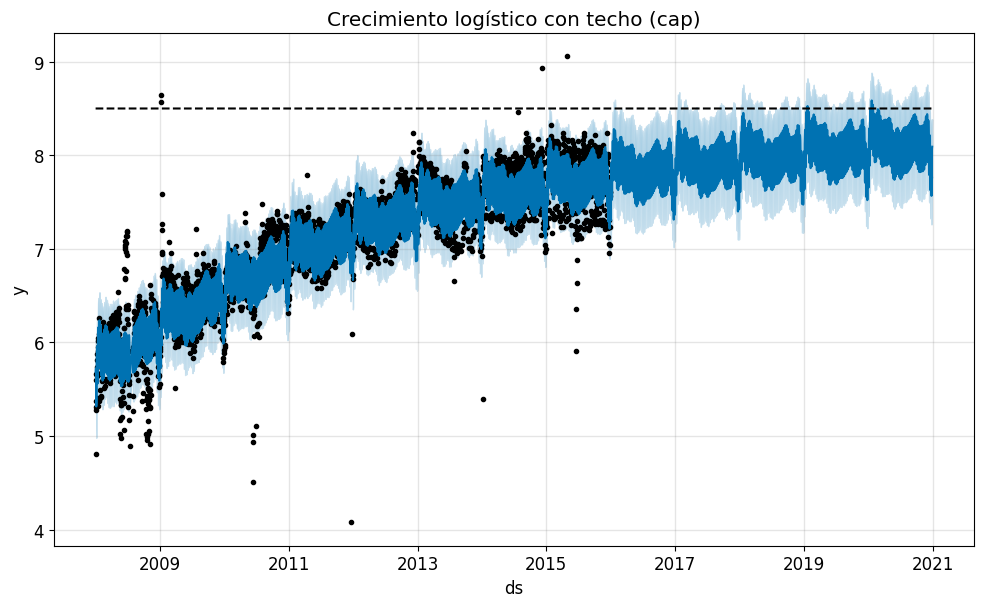

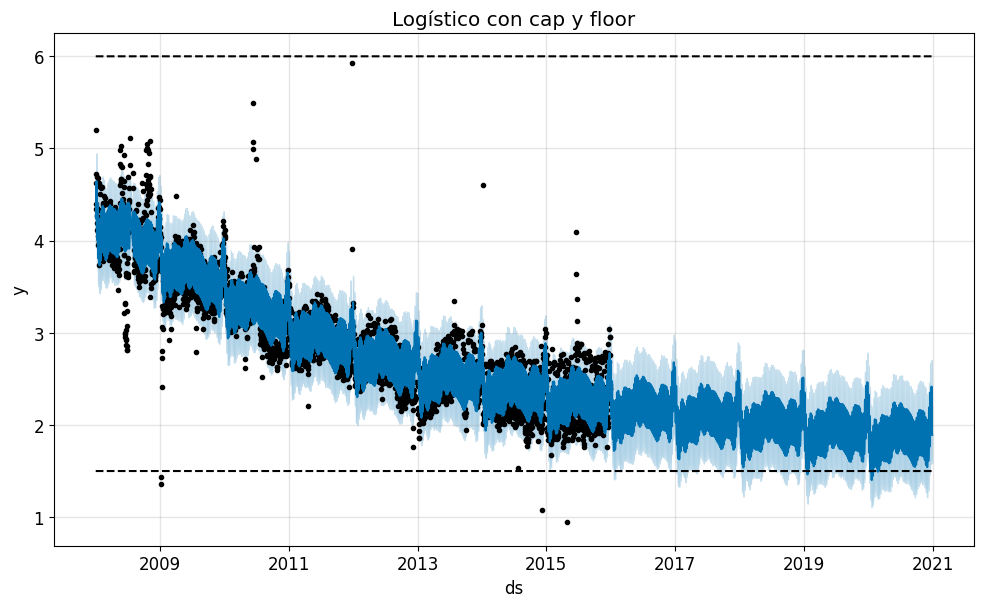

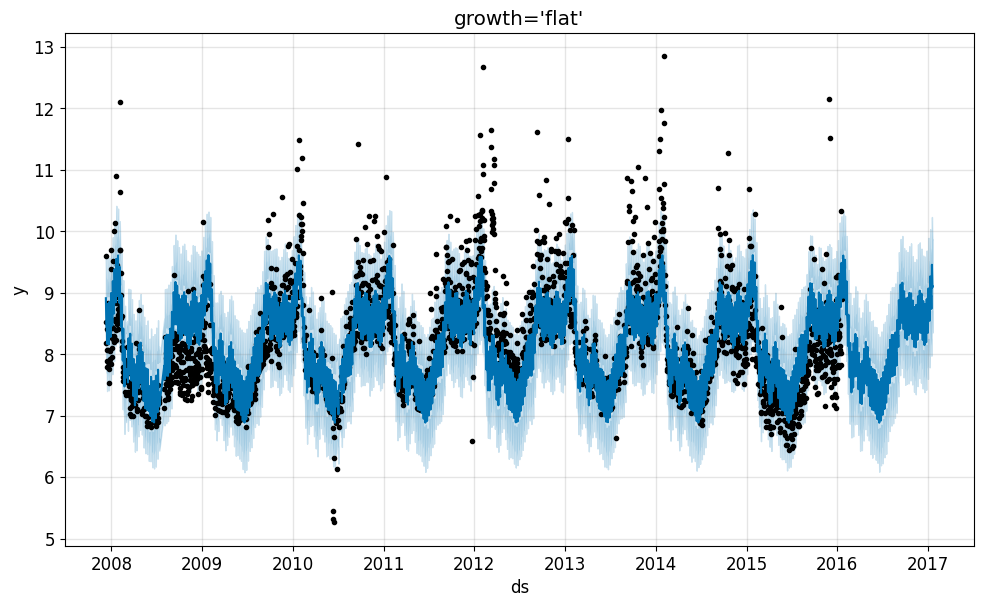

In [6]:
df_r = pd.read_csv(BASE + 'example_wp_log_R.csv')
df_r['cap'] = 8.5                                   # techo de saturación

m_log = Prophet(growth='logistic').fit(df_r)
fut = m_log.make_future_dataframe(periods=1826)
fut['cap'] = 8.5
fc = m_log.predict(fut)
fig = m_log.plot(fc)
plt.title('Crecimiento logístico con techo (cap)')
guardar(fig, '05_logistic_cap')

# Techo + piso (saturating minimum)
df_f = df_r.copy()
df_f['y'] = 10 - df_f['y']
df_f['cap'], df_f['floor'] = 6, 1.5
fut['cap'], fut['floor'] = 6, 1.5
m_fl = Prophet(growth='logistic').fit(df_f)
fig = m_fl.plot(m_fl.predict(fut))
plt.title('Logístico con cap y floor')
guardar(fig, '06_logistic_floor')

# Tendencia plana
m_flat = Prophet(growth='flat').fit(df)
fig = m_flat.plot(m_flat.predict(m_flat.make_future_dataframe(365)))
plt.title("growth='flat'")
guardar(fig, '07_flat')

## 5️⃣ Estacionalidad: aditiva vs multiplicativa, personalizada y condicional

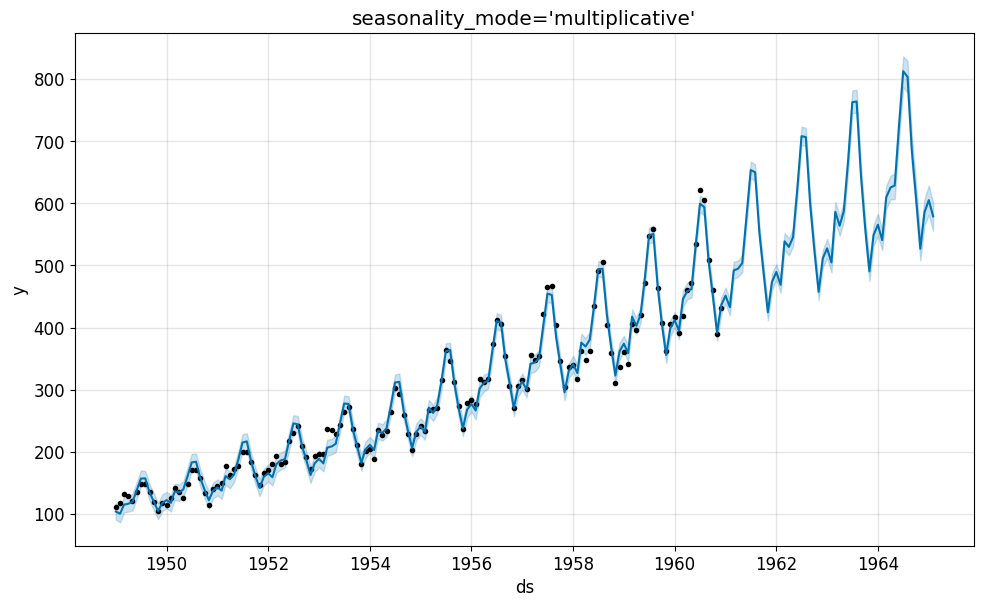

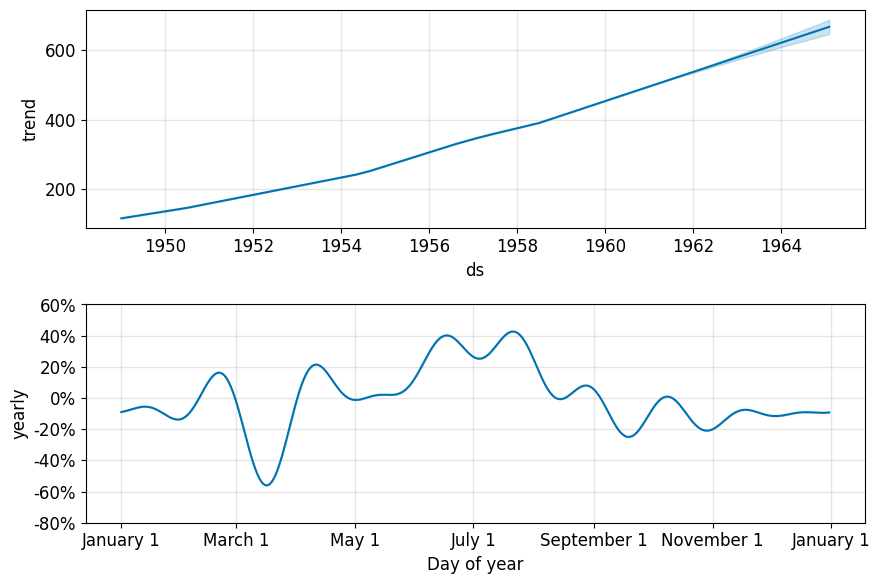

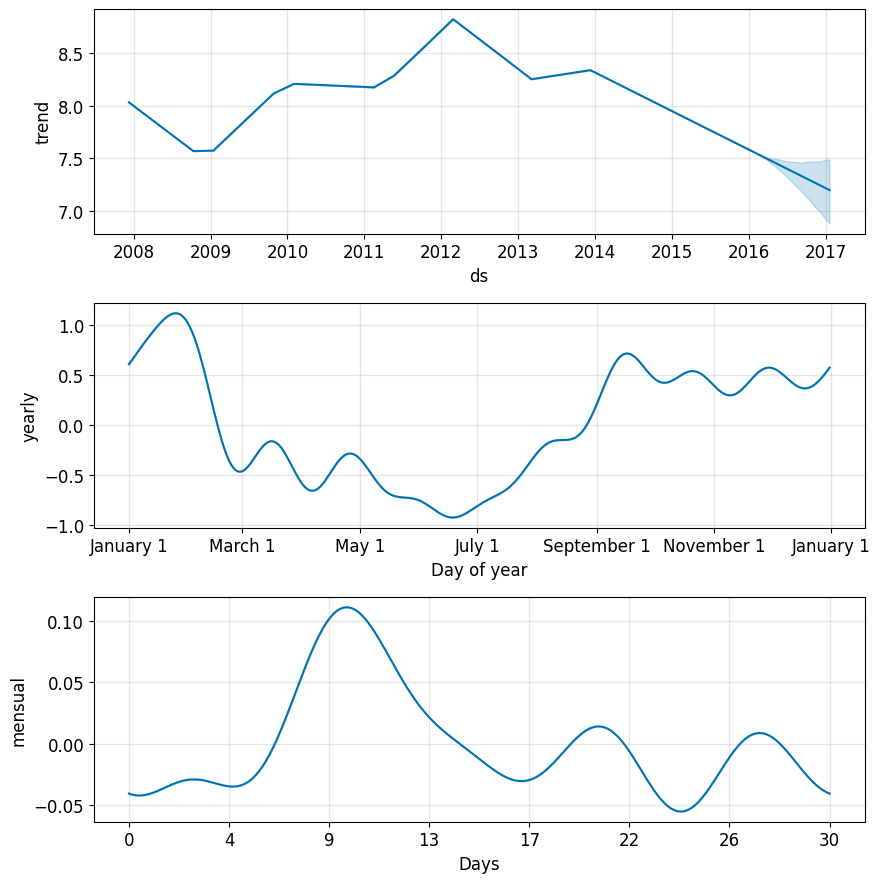

In [7]:
# Multiplicativa: la amplitud crece con la tendencia
df_air = pd.read_csv(BASE + 'example_air_passengers.csv')
m_mult = Prophet(seasonality_mode='multiplicative').fit(df_air)
fc = m_mult.predict(m_mult.make_future_dataframe(50, freq='MS'))
fig = m_mult.plot(fc)
plt.title("seasonality_mode='multiplicative'")
guardar(fig, '08_multiplicativa')
fig = m_mult.plot_components(fc)
guardar(fig, '09_componentes_mult')

# Estacionalidad personalizada (mensual)
m_mes = Prophet(weekly_seasonality=False)
m_mes.add_seasonality(name='mensual', period=30.5, fourier_order=5)
m_mes.fit(df)
fc = m_mes.predict(m_mes.make_future_dataframe(365))
fig = m_mes.plot_components(fc)
guardar(fig, '10_mensual')

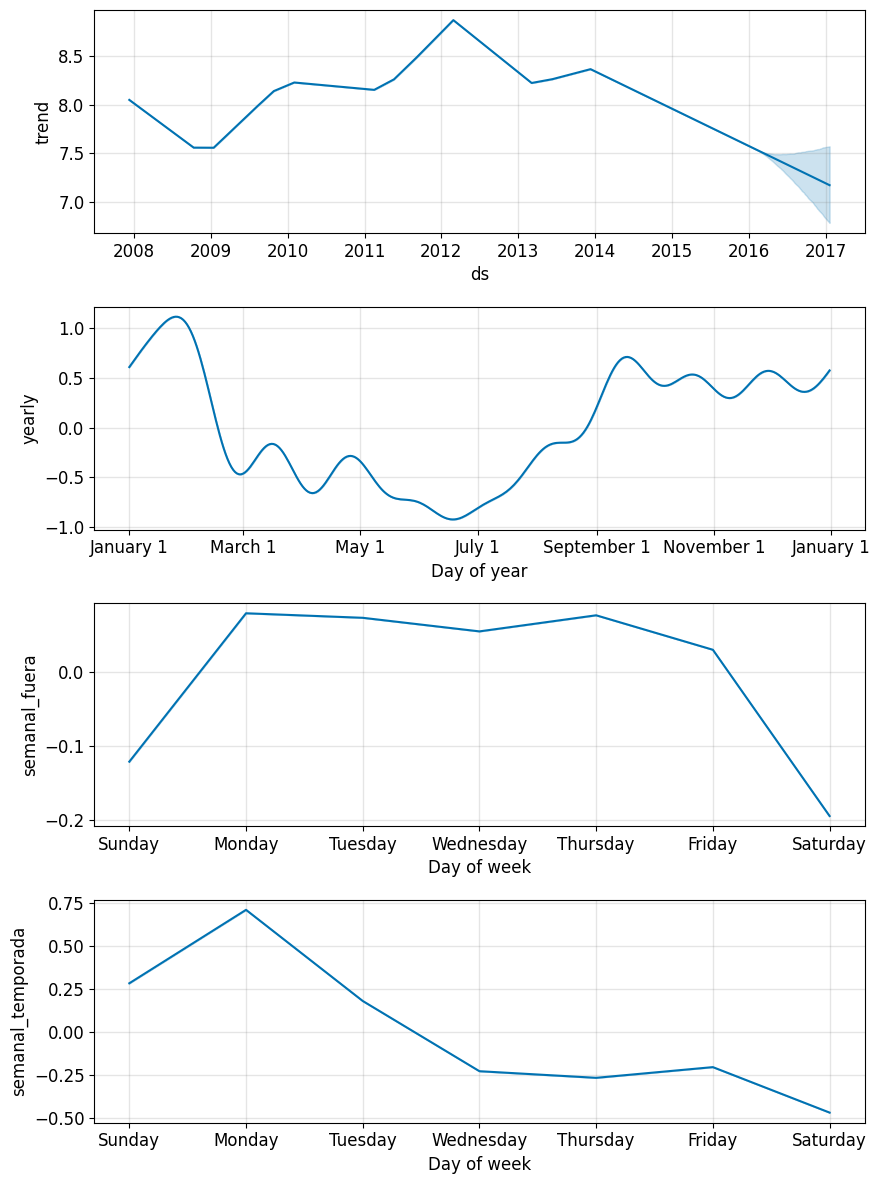

In [8]:
# Estacionalidad condicional: semana distinta dentro y fuera de temporada NFL
def es_temporada(ds):
    d = pd.to_datetime(ds)
    return d.month > 8 or d.month < 2

df_c = df.copy()
df_c['on_season'] = df_c['ds'].apply(es_temporada)
df_c['off_season'] = ~df_c['on_season']

m_cond = Prophet(weekly_seasonality=False)
m_cond.add_seasonality(name='semanal_temporada', period=7, fourier_order=3, condition_name='on_season')
m_cond.add_seasonality(name='semanal_fuera', period=7, fourier_order=3, condition_name='off_season')
m_cond.fit(df_c)

fut = m_cond.make_future_dataframe(365)
fut['on_season'] = fut['ds'].apply(es_temporada)
fut['off_season'] = ~fut['on_season']
fig = m_cond.plot_components(m_cond.predict(fut))
guardar(fig, '11_condicional')

## 6️⃣ Eventos y festivos: `holidays` y `add_country_holidays`

,ds,playoff,superbowl
34,2008-01-13,1.225122,0.0
35,2008-01-14,1.901134,0.0
361,2009-01-03,1.225122,0.0
362,2009-01-04,1.901134,0.0
730,2010-01-16,1.225122,0.0


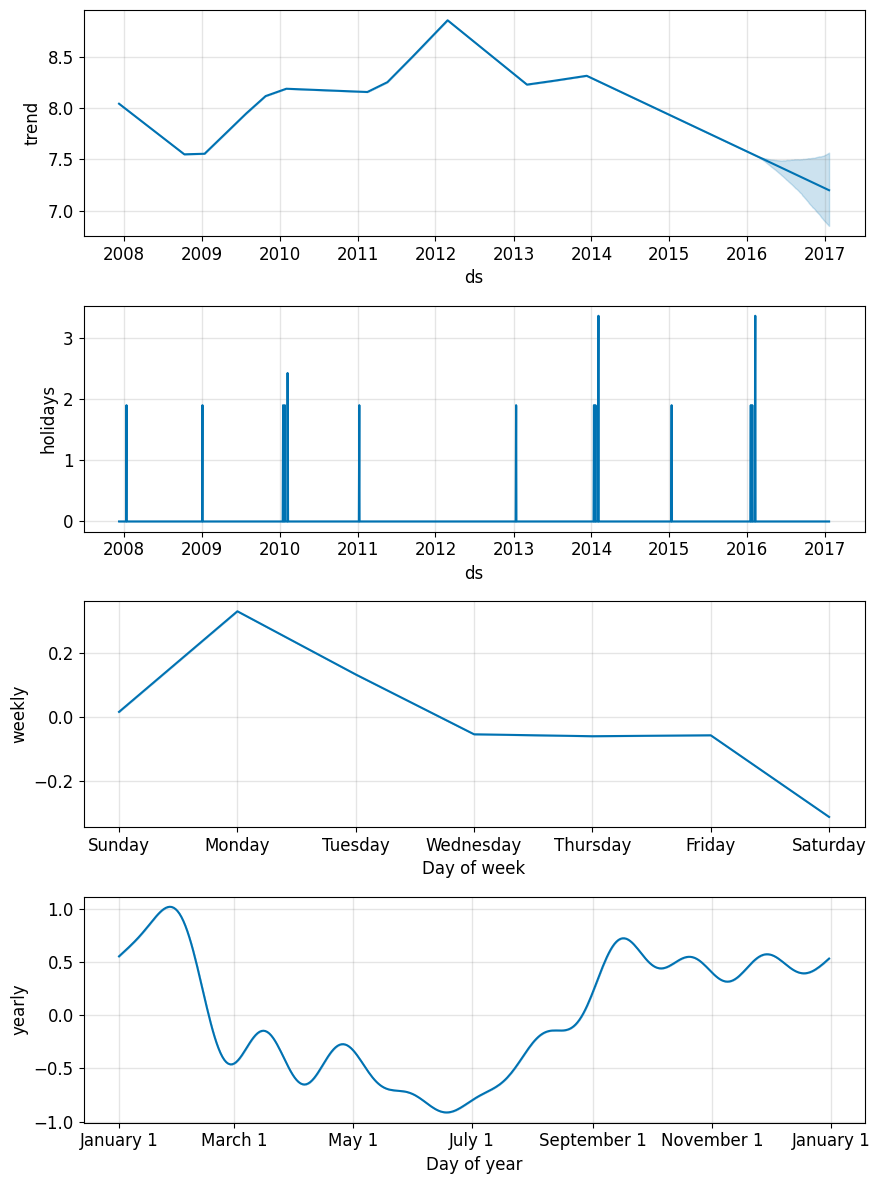

["New Year's Day", 'Memorial Day', 'Independence Day', 'Labor Day', 'Thanksgiving Day', 'Christmas Day', 'Christmas Day (observed)', 'Martin Luther King Jr. Day', "Washington's Birthday", 'Columbus Day'] ...


In [9]:
playoffs = pd.DataFrame({
    'holiday': 'playoff',
    'ds': pd.to_datetime(['2008-01-13','2009-01-03','2010-01-16','2010-01-24','2010-02-07',
                          '2011-01-08','2013-01-12','2014-01-12','2014-01-19','2014-02-02',
                          '2015-01-11','2016-01-17','2016-01-24','2016-02-07']),
    'lower_window': 0, 'upper_window': 1})
superbowls = pd.DataFrame({
    'holiday': 'superbowl',
    'ds': pd.to_datetime(['2010-02-07', '2014-02-02', '2016-02-07']),
    'lower_window': 0, 'upper_window': 1})
holidays = pd.concat([playoffs, superbowls])

m_h = Prophet(holidays=holidays, holidays_prior_scale=10).fit(df)
fc = m_h.predict(m_h.make_future_dataframe(365))
display(fc.loc[(fc['playoff'] + fc['superbowl']).abs() > 0, ['ds', 'playoff', 'superbowl']].head())
fig = m_h.plot_components(fc)
guardar(fig, '12_holidays')

# Festivos de un país con una línea
m_us = Prophet()
m_us.add_country_holidays(country_name='US')
m_us.fit(df)
print(m_us.train_holiday_names.tolist()[:10], '...')

## 7️⃣ Regresores externos: `add_regressor`

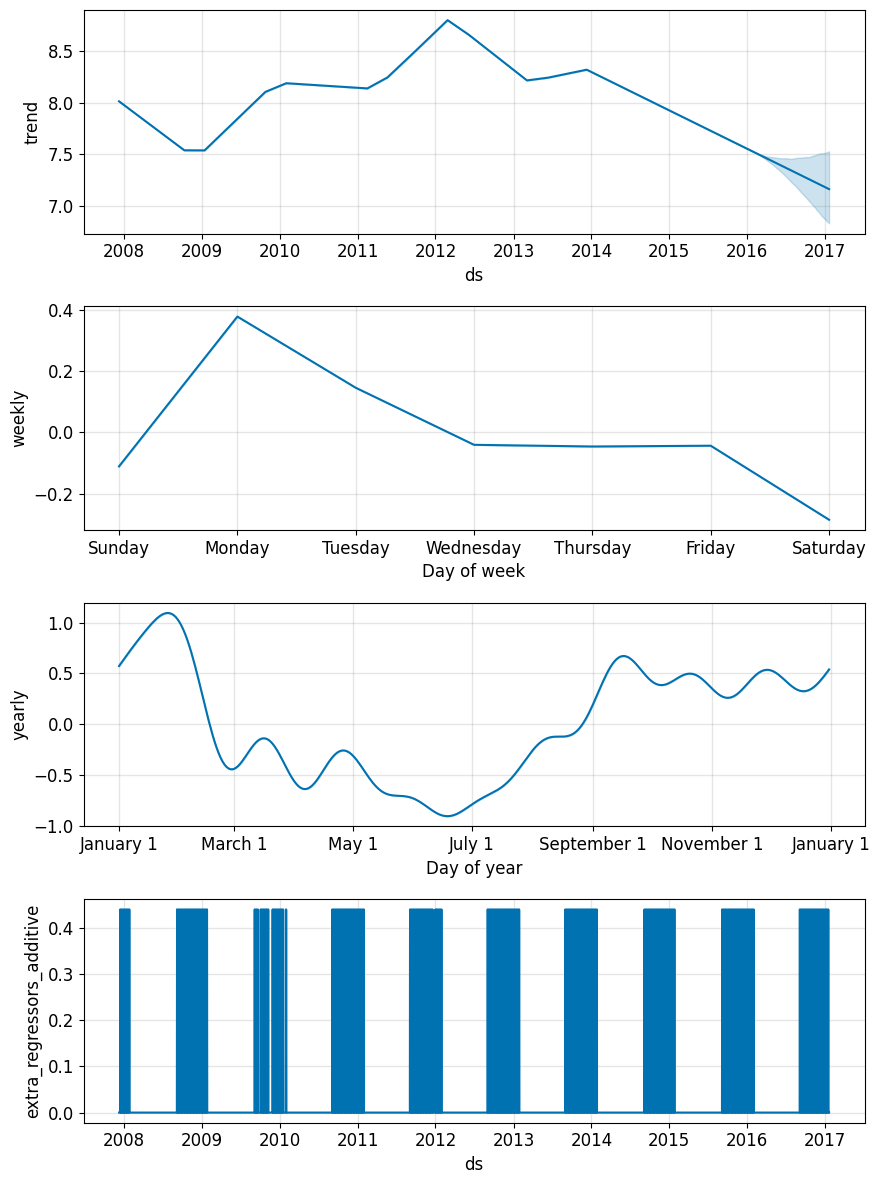

,regressor,regressor_mode,center,coef_lower,coef,coef_upper
0,nfl_sunday,additive,0.0,0.440656,0.440656,0.440656


In [10]:
def nfl_sunday(ds):
    d = pd.to_datetime(ds)
    return int(d.weekday() == 6 and (d.month > 8 or d.month < 2))

df_reg = df.copy()
df_reg['nfl_sunday'] = df_reg['ds'].apply(nfl_sunday)

m_reg = Prophet()
m_reg.add_regressor('nfl_sunday')
m_reg.fit(df_reg)

fut = m_reg.make_future_dataframe(365)
fut['nfl_sunday'] = fut['ds'].apply(nfl_sunday)
fc = m_reg.predict(fut)
fig = m_reg.plot_components(fc)
guardar(fig, '13_regresor')
regressor_coefficients(m_reg)

## 8️⃣ Outliers y datos faltantes
Prophet tolera `NaN` en `y`: basta con borrar el valor atípico.

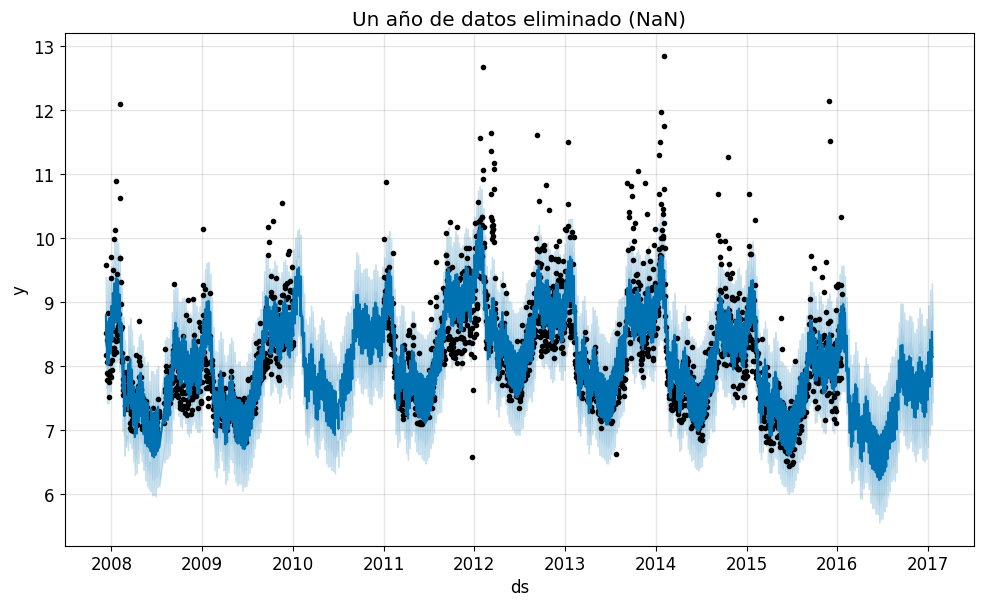

In [11]:
df_out = df.copy()
df_out.loc[(df_out['ds'] > '2010-01-01') & (df_out['ds'] < '2011-01-01'), 'y'] = None
m_out = Prophet().fit(df_out)
fig = m_out.plot(m_out.predict(m_out.make_future_dataframe(365)))
plt.title('Un año de datos eliminado (NaN)')
guardar(fig, '14_outliers')

## 9️⃣ Incertidumbre: `interval_width`, `predictive_samples` y MCMC

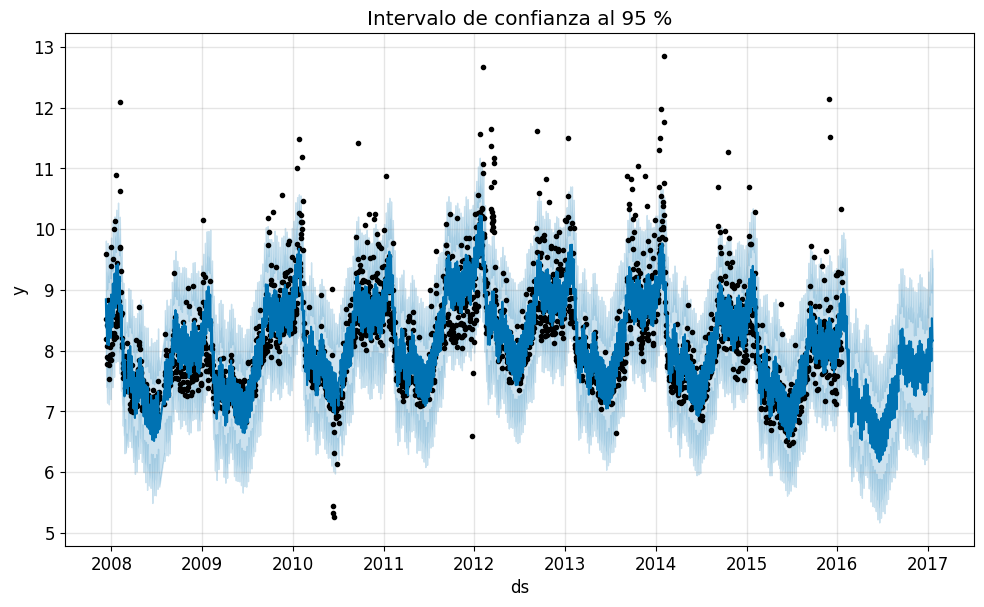

{'yhat': (3270, 1000), 'trend': (3270, 1000)}


In [12]:
m_u = Prophet(interval_width=0.95).fit(df)
fut = m_u.make_future_dataframe(365)
fc = m_u.predict(fut)
fig = m_u.plot(fc)
plt.title('Intervalo de confianza al 95 %')
guardar(fig, '15_intervalo')

muestras = m_u.predictive_samples(fut)
print({k: v.shape for k, v in muestras.items()})

chain 1:   0%|          | 0/100 [00:00<?, ?it/s, (Warmup)]

chain 2:   0%|          | 0/100 [00:00<?, ?it/s, (Warmup)]

chain 3:   0%|          | 0/100 [00:00<?, ?it/s, (Warmup)]

chain 4:   0%|          | 0/100 [00:00<?, ?it/s, (Warmup)]

Exception: normal_id_glm_lpdf: Matrix of independent variables is inf, but must be finite! (in 'prophet.stan', line 137, column 2 to line 142, column 4)
	Exception: normal_id_glm_lpdf: Matrix of independent variables is inf, but must be finite! (in 'prophet.stan', line 137, column 2 to line 142, column 4)
	Exception: normal_id_glm_lpdf: Scale vector is 0, but must be positive finite! (in 'prophet.stan', line 137, column 2 to line 142, column 4)
	Exception: normal_id_glm_lpdf: Scale vector is 0, but must be positive finite! (in 'prophet.stan', line 137, column 2 to line 142, column 4)
Exception: normal_id_glm_lpdf: Matrix of independent variables is inf, but must be finite! (in 'prophet.stan', line 137, column 2 to line 142, column 4)
	Exception: normal_id_glm_lpdf: Matrix of independent variables is inf, but must be finite! (in 'prophet.stan', line 137, column 2 to line 142, column 4)
	Exception: normal_id_glm_lpdf: Scale vector is 0, but must be positive finite! (in 'prophet.stan', li

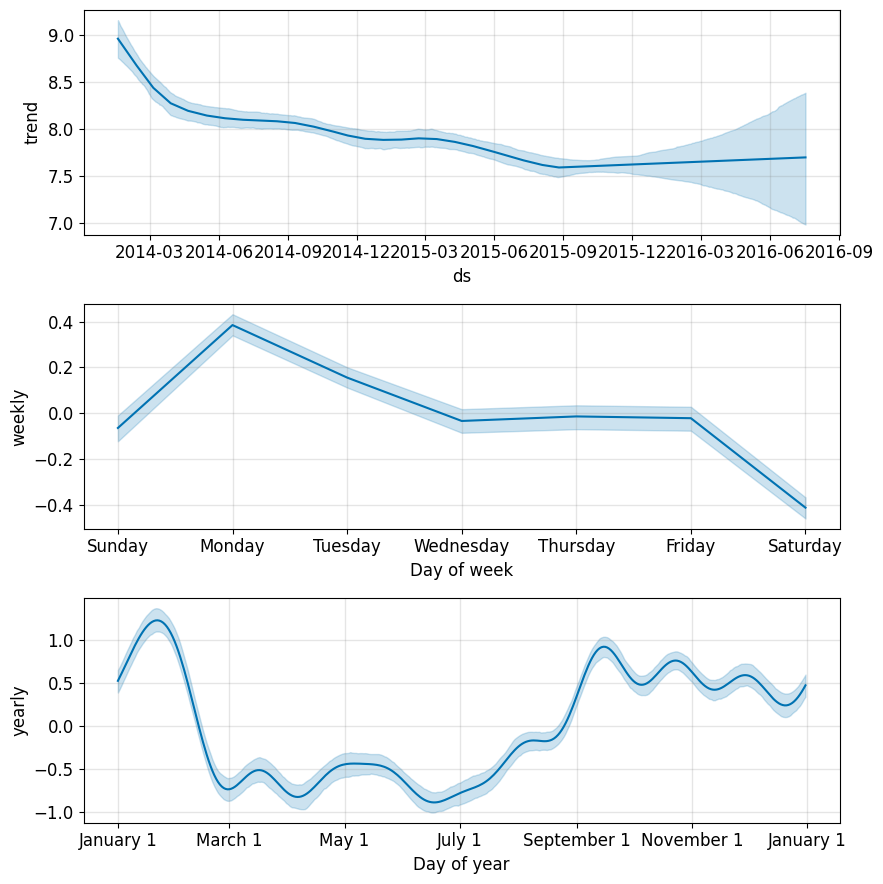

In [13]:
# ⏱️ Opcional (tarda 1-3 min): incertidumbre también en estacionalidad con MCMC
m_mc = Prophet(mcmc_samples=100).fit(df.tail(730))
fc = m_mc.predict(m_mc.make_future_dataframe(180))
fig = m_mc.plot_components(fc)
guardar(fig, '16_mcmc')

## 🔟 Datos sub-diarios (cada 5 min)

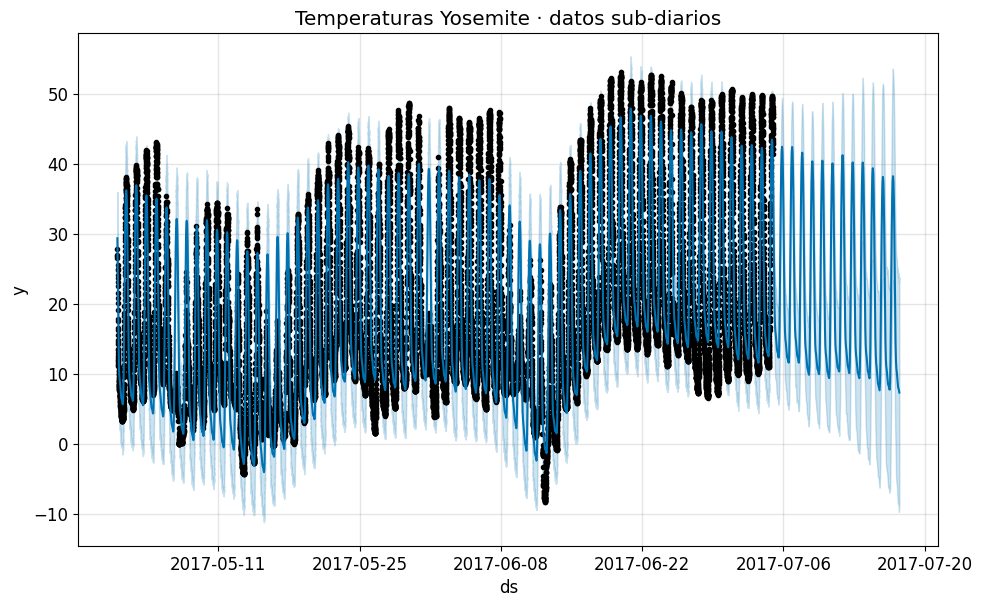

In [14]:
df_y = pd.read_csv(BASE + 'example_yosemite_temps.csv')
m_y = Prophet(changepoint_prior_scale=0.01).fit(df_y)
fut = m_y.make_future_dataframe(periods=300, freq='h')
fig = m_y.plot(m_y.predict(fut))
plt.title('Temperaturas Yosemite · datos sub-diarios')
guardar(fig, '17_subdiario')

## 1️⃣1️⃣ Diagnóstico: validación cruzada y métricas

,horizon,mse,rmse,mae,mape,mdape,smape,coverage
0,37 days,0.493308,0.702359,0.505572,0.058609,0.049809,0.058885,0.679077
1,38 days,0.499088,0.706462,0.510553,0.059186,0.049566,0.059521,0.677935
2,39 days,0.521237,0.721968,0.516646,0.059786,0.049587,0.060246,0.675194
3,40 days,0.528369,0.726890,0.519464,0.060087,0.049480,0.060616,0.678849
4,41 days,0.535647,0.731879,0.520392,0.060159,0.049566,0.060751,0.683874


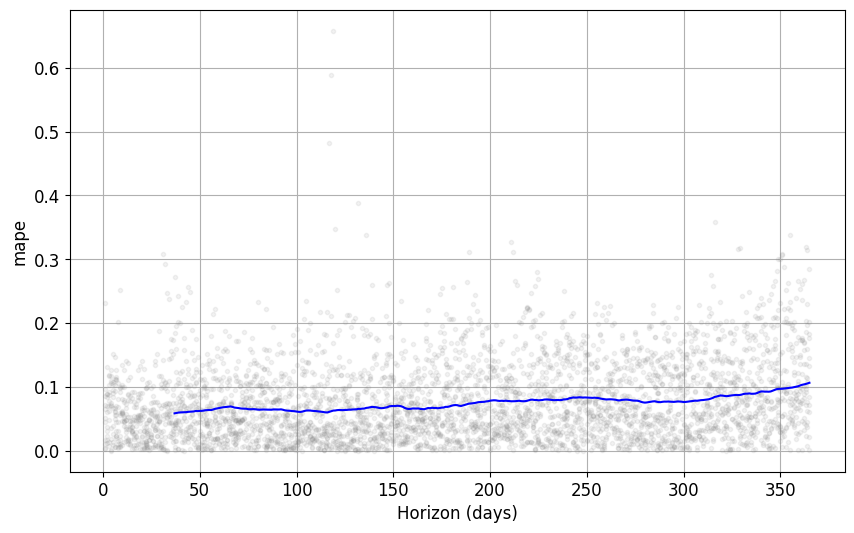

In [15]:
m_cv = Prophet().fit(df)
df_cv = cross_validation(m_cv, initial='730 days', period='180 days',
                         horizon='365 days', parallel='processes')
df_p = performance_metrics(df_cv)
display(df_p.head())

fig = plot_cross_validation_metric(df_cv, metric='mape')
guardar(fig, '18_cv_mape')

In [16]:
# Ajuste de hiperparámetros (grid search pequeño)
grid = {'changepoint_prior_scale': [0.01, 0.5], 'seasonality_prior_scale': [0.1, 10.0]}
resultados = []
for valores in itertools.product(*grid.values()):
    p = dict(zip(grid.keys(), valores))
    mm = Prophet(**p).fit(df)
    cv = cross_validation(mm, initial='1825 days', period='365 days',
                          horizon='90 days', parallel='processes')
    rmse = performance_metrics(cv, rolling_window=1)['rmse'].values[0]
    resultados.append({**p, 'rmse': rmse})
pd.DataFrame(resultados).sort_values('rmse')

,changepoint_prior_scale,seasonality_prior_scale,rmse
0,0.01,0.1,0.600743
1,0.01,10.0,0.602945
3,0.50,10.0,0.661558
2,0.50,0.1,0.663060


## 1️⃣2️⃣ Gráficas interactivas con Plotly

In [17]:
# Creamos clases seguras para evitar el error de ambigüedad booleana en Pandas con los asserts de Prophet
class SafeDataFrame(pd.DataFrame):
    def __bool__(self):
        return not self.empty

class SafeSeries(pd.Series):
    def __bool__(self):
        return not self.empty

m_p = Prophet().fit(df)

# Envolvemos los atributos conflictivos para que pasen las validaciones de Prophet
m_p.history = SafeDataFrame(m_p.history)
m_p.changepoints = SafeSeries(m_p.changepoints)

fc_p = m_p.predict(m_p.make_future_dataframe(365))
plot_plotly(m_p, fc_p).show()
plot_components_plotly(m_p, fc_p).show()

## 1️⃣3️⃣ Guardar, cargar y reentrenar rápido (`warm_start`)

In [18]:
# Serialización JSON
with open(f'{OUT}/modelo_prophet.json', 'w') as f:
    f.write(model_to_json(m_p))
with open(f'{OUT}/modelo_prophet.json') as f:
    m_cargado = model_from_json(f.read())
print('Modelo recargado ✔', m_cargado.predict(m_cargado.make_future_dataframe(30)).shape)

# Warm start: reentrenar con datos nuevos usando parámetros previos
m_old = Prophet().fit(df.iloc[:-30])
t = time.time(); Prophet().fit(df); t_frio = time.time() - t
t = time.time(); Prophet().fit(df, init=warm_start_params(m_old)); t_tibio = time.time() - t
print(f'Sin warm start: {t_frio:.2f}s · Con warm start: {t_tibio:.2f}s')

Modelo recargado ✔ (2935, 19)
Sin warm start: 1.51s · Con warm start: 0.90s


## 🎬 Video: el modelo "aprendiendo" mes a mes (backtesting animado)
Entrena Prophet con cortes sucesivos y compara el pronóstico a 180 días contra lo que pasó realmente.

In [19]:
from matplotlib.animation import FuncAnimation, FFMpegWriter, PillowWriter
from IPython.display import Video

cortes = pd.date_range('2010-06-30', '2015-06-30', periods=12).normalize()
frames = []
for c in cortes:
    mm = Prophet().fit(df[df.ds <= c])
    frames.append((c, mm.predict(mm.make_future_dataframe(180))))

fig, ax = plt.subplots(figsize=(12, 6.75))
def actualizar(i):
    ax.clear()
    c, fc = frames[i]
    vis = df[df.ds <= c + pd.Timedelta(days=180)]
    ax.scatter(vis.ds, vis.y, s=4, c='gray', alpha=.5, label='Real')
    ax.plot(fc.ds, fc.yhat, c='#2a7fff', lw=1.6, label='Prophet')
    ax.fill_between(fc.ds, fc.yhat_lower, fc.yhat_upper, color='#2a7fff', alpha=.2)
    ax.axvline(c, c='red', ls='--', label='Corte')
    ax.set_xlim(df.ds.min(), df.ds.max())
    ax.set_ylim(df.y.min() - .2, df.y.max() + .2)
    ax.set_title(f'Entrenado hasta {c.date()} → pronóstico a 180 días')
    ax.legend(loc='upper left')

anim = FuncAnimation(fig, actualizar, frames=len(frames), interval=600)
anim.save(f'{OUT}/prophet_backtest.mp4', writer=FFMpegWriter(fps=2, bitrate=3000))
anim.save(f'{OUT}/prophet_backtest.gif', writer=PillowWriter(fps=2))
plt.close(fig)
Video(f'{OUT}/prophet_backtest.mp4', embed=True, width=800)

## 🖼️ Imagen final para el video: tabla de funciones (vertical 1080×1920)

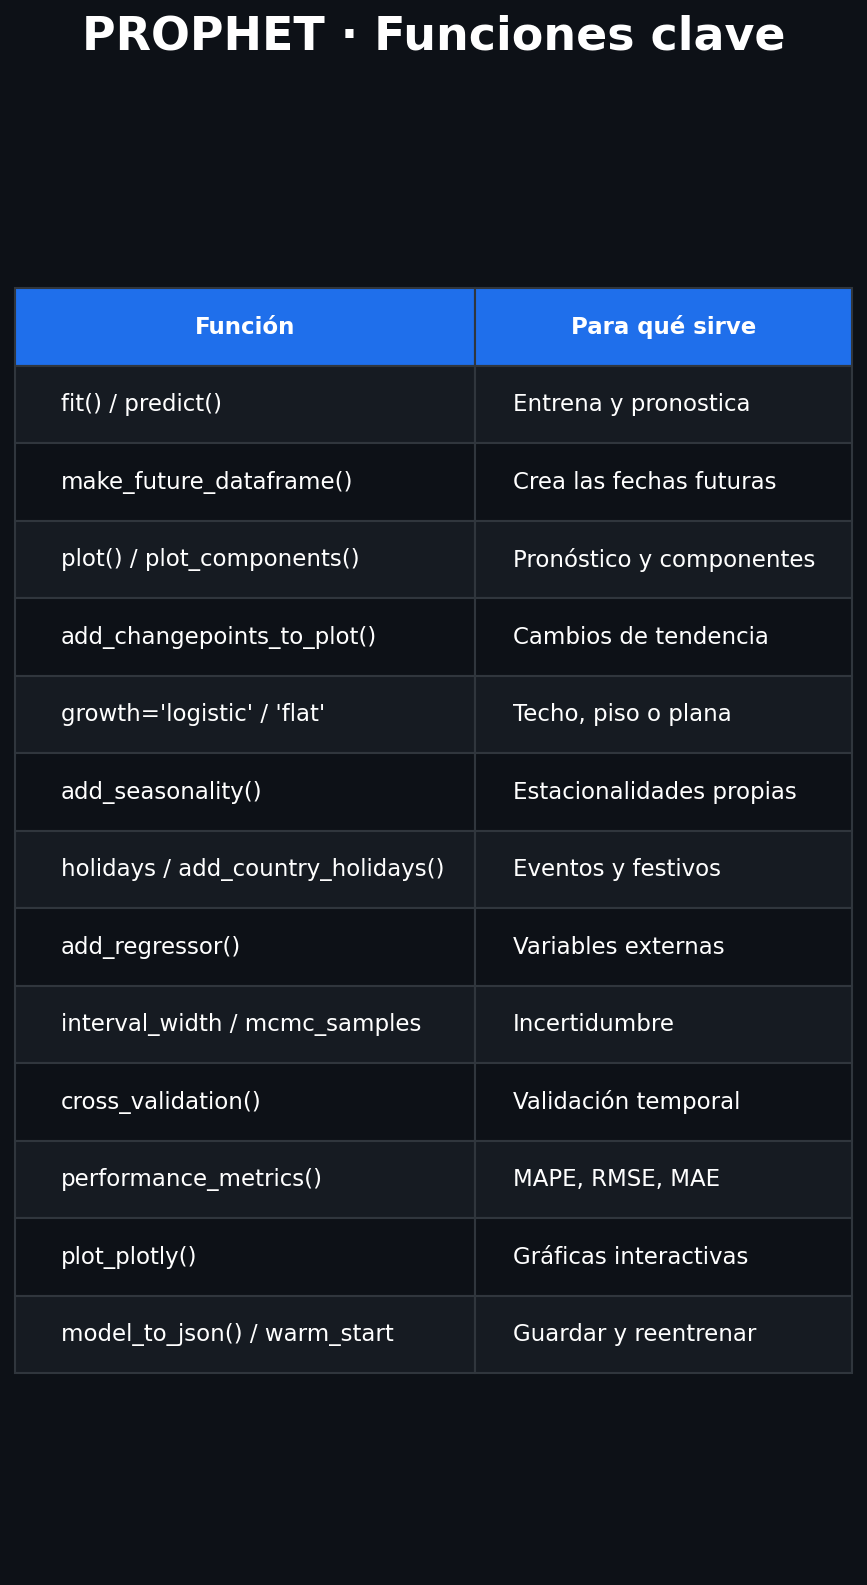

In [20]:
filas = [
    ('fit() / predict()',                  'Entrena y pronostica'),
    ('make_future_dataframe()',            'Crea las fechas futuras'),
    ('plot() / plot_components()',         'Pronóstico y componentes'),
    ('add_changepoints_to_plot()',         'Cambios de tendencia'),
    ("growth='logistic' / 'flat'",         'Techo, piso o plana'),
    ('add_seasonality()',                  'Estacionalidades propias'),
    ('holidays / add_country_holidays()',  'Eventos y festivos'),
    ('add_regressor()',                    'Variables externas'),
    ('interval_width / mcmc_samples',      'Incertidumbre'),
    ('cross_validation()',                 'Validación temporal'),
    ('performance_metrics()',              'MAPE, RMSE, MAE'),
    ('plot_plotly()',                      'Gráficas interactivas'),
    ('model_to_json() / warm_start',       'Guardar y reentrenar'),
]
fig, ax = plt.subplots(figsize=(7.2, 12.8), dpi=150)
fig.patch.set_facecolor('#0d1117'); ax.axis('off')
ax.set_title('PROPHET · Funciones clave', color='white', fontsize=22, fontweight='bold', pad=20)
tabla = ax.table(cellText=filas, colLabels=['Función', 'Para qué sirve'],
                 colWidths=[0.55, 0.45], loc='center', cellLoc='left')
tabla.auto_set_font_size(False); tabla.set_fontsize(11); tabla.scale(1, 3.1)
for (r, c), celda in tabla.get_celld().items():
    celda.set_edgecolor('#30363d')
    celda.set_facecolor('#1f6feb' if r == 0 else ('#161b22' if r % 2 else '#0d1117'))
    celda.get_text().set_color('white')
    if r == 0: celda.get_text().set_fontweight('bold')
fig.savefig(f'{OUT}/19_tabla_final.png', dpi=150, facecolor=fig.get_facecolor(), bbox_inches='tight')
plt.show()

## 📦 Descargar todo (imágenes, mp4, gif y modelo)

In [21]:
!zip -qr /content/prophet_assets.zip /content/prophet_assets
from google.colab import files
files.download('/content/prophet_assets.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>